In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("years_experience_vs_salary.csv")

In [3]:
df.sample(25)

,Years_of_Experience,Salary
728,5.4,71066.41
313,24.1,191967.33
383,22.0,164824.23
464,24.1,186281.76
469,24.1,179196.02
998,23.8,186140.88
511,10.7,124799.20
295,13.3,117467.19
542,6.1,74097.38
100,1.3,63470.56


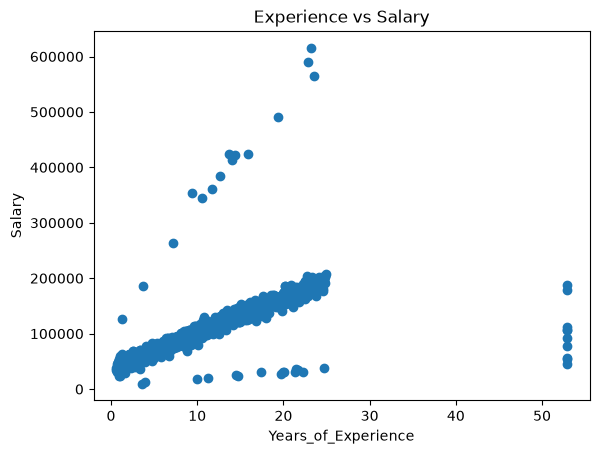

In [7]:
plt.scatter(df['Years_of_Experience'], df['Salary'])
plt.xlabel("Years_of_Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary")
plt.show()


In [8]:
df.isnull().sum()

Years_of_Experience    40
Salary                 26
dtype: int64

In [9]:
median_experience = df['Years_of_Experience'].median()
median_experience

np.float64(12.850000000000001)

In [10]:
median_salary = df['Salary'].median()
median_salary

np.float64(116878.04000000001)

In [17]:
df['Years_of_Experience'].fillna(df['Years_of_Experience'].median(), inplace=True)
df['Salary'].fillna(df['Salary'].median(), inplace=True)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18264\2271445501.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Years_of_Experience'].fillna(df['Years_of_Experience'].median(), inplace=True)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18264\2271445501.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame 

0       99317.12
1      178968.50
2      157861.62
3      138471.05
4       67574.29
         ...    
995     42274.27
996    179438.03
997     59742.07
998    186140.88
999    103737.05
Name: Salary, Length: 1000, dtype: float64

In [28]:
Q1 = df['Years_of_Experience'].quantile(0.25)
Q3 = df['Years_of_Experience'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df['Years_of_Experience'] >= lower_bound) & (df['Years_of_Experience'] <= upper_bound)]


In [29]:
print(df.isnull().sum())


Years_of_Experience     0
Salary                 26
Experience_Group        0
dtype: int64


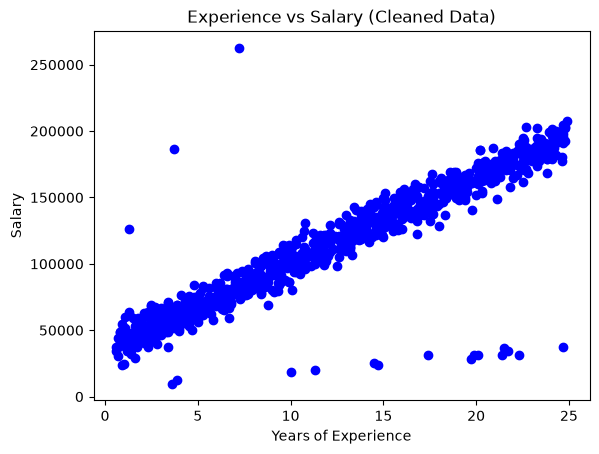

In [30]:
import matplotlib.pyplot as plt

plt.scatter(df['Years_of_Experience'], df['Salary'], color='blue', marker='o')
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary (Cleaned Data)")
plt.show()


In [49]:
import numpy as np

def fix_salary_outlier(row, df):
    exp = row['Years_of_Experience']
    sal = row['Salary']
    
    
    neigh = df[(df['Years_of_Experience'] >= exp-2) & 
               (df['Years_of_Experience'] <= exp+2)]
    
    median_sal = neigh['Salary'].median()
    std_sal = neigh['Salary'].std()
    

    if abs(sal - median_sal) > 2*std_sal:
        return median_sal
    else:
        return sal

df['Salary'] = df.apply(lambda row: fix_salary_outlier(row, df), axis=1)


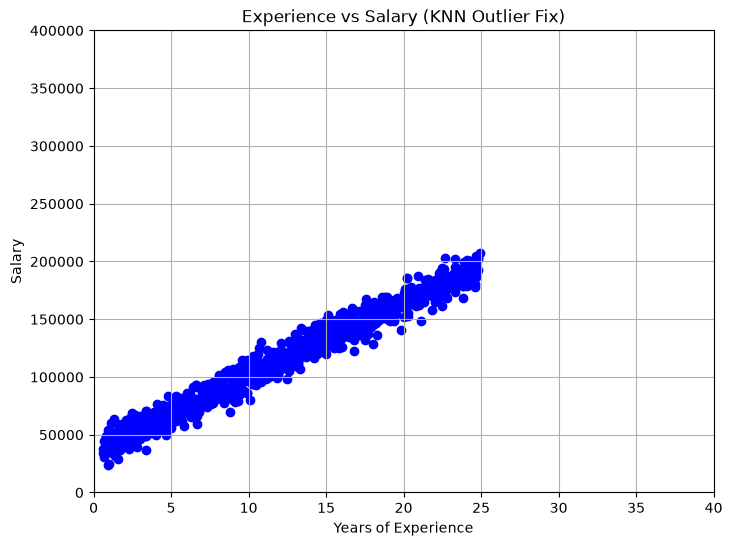

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(df['Years_of_Experience'], df['Salary'], color='blue', marker='o')
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary (KNN Outlier Fix)")
plt.xlim(0, 40)          
plt.ylim(0, 400000)      
plt.grid(True)
plt.show()


In [60]:
import numpy as np

def fix_salary_outlier(row, df):
    exp = row['Years_of_Experience']
    sal = row['Salary']
    
    neigh = df[(df['Years_of_Experience'] >= exp-2) & 
               (df['Years_of_Experience'] <= exp+2)]
    
    median_sal = neigh['Salary'].median()
    std_sal = neigh['Salary'].std()
    
    if pd.isna(sal):
        return median_sal
    elif abs(sal - median_sal) > 2*std_sal:
        return median_sal
    else:
        return sal

df['Salary'] = df.apply(lambda row: fix_salary_outlier(row, df), axis=1)


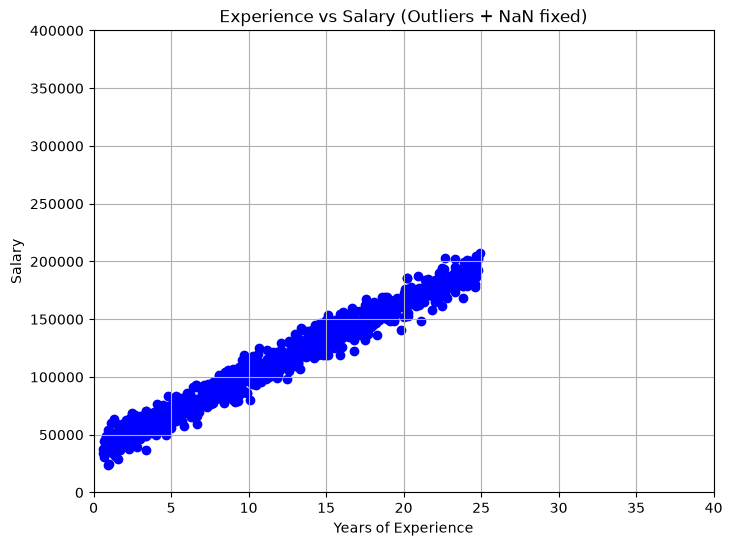

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(df['Years_of_Experience'], df['Salary'], color='blue')
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary (Outliers + NaN fixed)")
plt.xlim(0, 40)
plt.ylim(0, 400000)
plt.grid(True)
plt.show()


In [63]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[['Years_of_Experience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


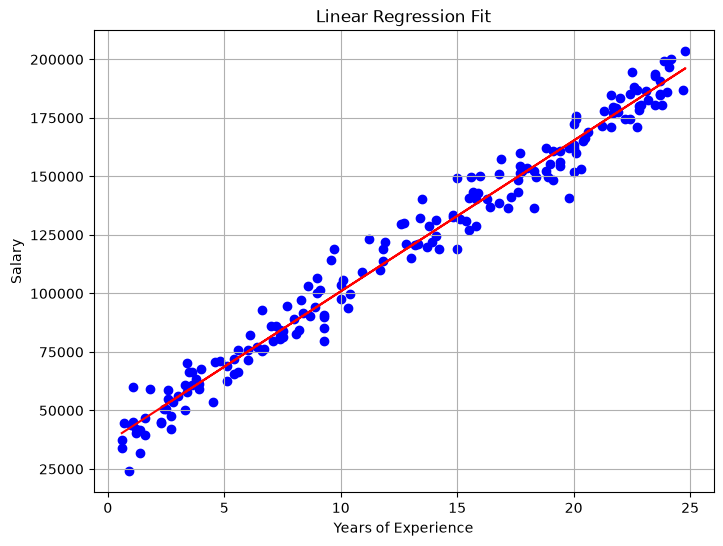

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(X_test, y_test, color='blue')
plt.plot(X_test, y_pred, color='red')
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression Fit")
plt.grid(True)
plt.show()


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)


In [69]:
rmse

np.float64(7286.145266106474)

In [70]:
r2

0.9768414418968074

In [71]:
mae

5728.715547714346